In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

T_a = np.load("T_to_glass.npy", mmap_mode="r")
T_b = np.load("T_b_to_glass.npy", mmap_mode="r")

In [31]:
def centered(p):
    """Wrapped phase -> zero-mean real map around its circular mean (sign flip -> negation)."""
    z = np.exp(1j * p)
    x = np.angle(z * np.conj(z.mean()))
    return x - x.mean()

def _peak_offset(cm, c0, cp):
    d = cm - 2 * c0 + cp
    return 0.0 if d == 0 else 0.5 * (cm - cp) / d

def signed_shift(ref, img, max_shift=40):
    """Sub-pixel (dy, dx) rolling img onto ref, and the signed normalized correlation r at that shift.
    r < 0 means img has the opposite phase sign."""
    c = np.fft.ifft2(np.fft.fft2(ref) * np.fft.fft2(img).conj()).real
    c = np.fft.fftshift(c) / (np.linalg.norm(ref) * np.linalg.norm(img))
    H, W = c.shape; cy, cx = H // 2 - max_shift, W // 2 - max_shift
    win = np.abs(c[cy:cy + 2 * max_shift + 1, cx:cx + 2 * max_shift + 1])
    iy, ix = np.unravel_index(win.argmax(), win.shape)
    py, px = cy + iy, cx + ix
    dy = iy - max_shift + _peak_offset(*np.abs(c[py - 1:py + 2, px]))
    dx = ix - max_shift + _peak_offset(*np.abs(c[py, px - 1:px + 2]))
    return dy, dx, c[py, px]

def register_wavelengths(ref_stack, roi, max_shift=40):
    """Chain neighbouring wavelengths of ref_stack (wvl, Y, X): cumulative sign and shift relative to wvl 0."""
    X = [centered(p[roi]) for p in ref_stack]
    signs, shifts, corr = [1], [np.zeros(2)], [1.0]
    for k in range(1, len(X)):
        dy, dx, r = signed_shift(X[k - 1], X[k], max_shift)
        signs.append(signs[-1] * int(np.sign(r)))
        shifts.append(shifts[-1] + (dy, dx))
        corr.append(r)
    return np.array(signs), np.array(shifts), np.array(corr)

def apply_registration(stack, signs, shifts):
    """Flip signs (N, wvl), roll each wavelength by integer shifts (wvl, 2), crop to the common valid window."""
    N, L, H, W = stack.shape
    y0, x0 = shifts.max(0).clip(min=0)
    y1, x1 = np.array([H, W]) + shifts.min(0).clip(max=0)
    out = np.empty((N, L, y1 - y0, x1 - x0), stack.dtype)
    for w, (dy, dx) in enumerate(shifts):
        out[:, w] = stack[:, w, y0 - dy:y1 - dy, x0 - dx:x1 - dx] * signs[:, w, None, None].astype(stack.dtype)
    return out


# Same wavelength registration as the phase stacks in vp_aia_vs_aia_N_wvl_stack.ipynb
reg_roi = (slice(250, 1250), slice(1000, 2000))
ref = np.load("phi_N_stack_aia.npy", mmap_mode="r")[-1]   # largest N of AIA
_, shifts_f, _ = register_wavelengths(ref, reg_roi)
shifts = np.rint(shifts_f).astype(int)

ones = np.ones((1, len(shifts)), int)
T_a = apply_registration(T_a[None], ones, shifts)[0]
T_b = apply_registration(T_b[None], ones, shifts)[0]
ratio = T_a/T_b

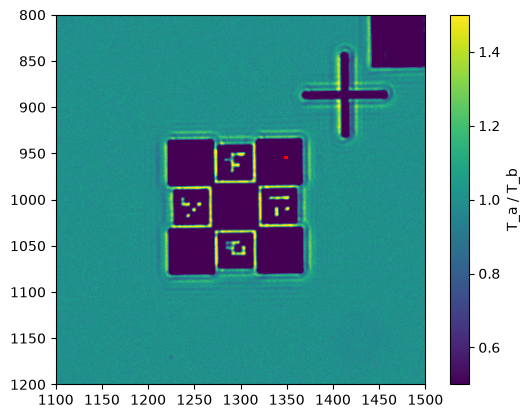

In [39]:
xc, yc, side = 1350, 955, 2
x0, y0 = xc - side//2, yc - side//2   # top-left corner of the ROI

fig, ax = plt.subplots()
im = ax.imshow(T_a[2])
ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), side, side, fill=False, edgecolor="red", linewidth=1.5))
ax.set_xlim(1100, 1500)
ax.set_ylim(1200, 800)   # imshow has y pointing down
im.set_clim([0.5, 1.5])
fig.colorbar(im, ax=ax, label="T_a / T_b")
plt.show()

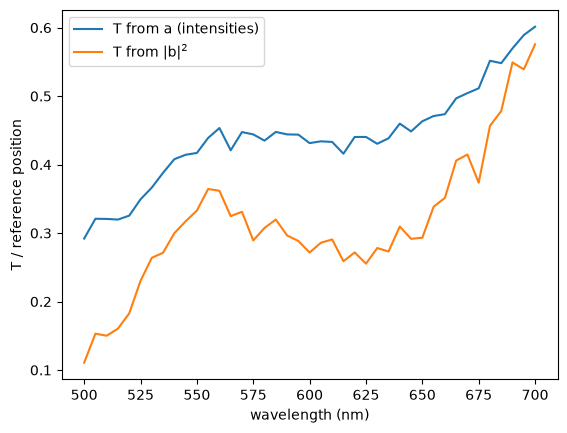

In [38]:
wvl = np.linspace(500, 700, 41)
roi = (slice(None), slice(y0, y0 + side), slice(x0, x0 + side))

plt.figure()
plt.plot(wvl, T_a[roi].mean(axis=(1, 2)), label="T from a (intensities)")
plt.plot(wvl, T_b[roi].mean(axis=(1, 2)), label="T from |b|$^2$")
plt.xlabel("wavelength (nm)"); plt.ylabel("T / reference position")
plt.legend()
plt.show()